# AA3 · Parcial II · Cuaderno 1: Recurrentes

**Alumno:** Edgar Mauricio Trejo Delgado

**Datos:** AAPL (Apple) descargado de Yahoo Finanzas con `yfinance` · `period="5y"`, `interval="1d"`, `horizonte=1`, `ventana=30`



## 1. Datos
Cuaderno de pronóstico de la Práctica 3, parte A. El usuario solo elige `ticker` y `usar_volumen` en el formulario; `period`, `interval`, `horizonte` y `ventana` son los mismos de la práctica.

Se aplican las reglas de los Bloques 2 y 3: **división cronológica** 70/15/15, **normalización solo con el entrenamiento** y **ventanas** con `timeseries_dataset_from_array`.

In [1]:
import os
import sys
import time
import importlib.util
# yfinance se importa ANTES que torch y keras: en Colab, si se importa después, la descarga falla.
import yfinance as yf

EN_COLAB = importlib.util.find_spec("google.colab") is not None
os.environ["KERAS_BACKEND"] = "torch"   # Keras 3 con PyTorch, como en la práctica

import torch
import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
DIR_MODELOS = os.path.join("modelos", "C1")
os.makedirs(DIR_MODELOS, exist_ok=True)

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print(f"Entorno: {'Google Colab' if EN_COLAB else 'Local'} · Python {sys.version.split()[0]}")
print(f"Keras {keras.__version__} · backend: {keras.backend.backend()} · PyTorch {torch.__version__}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no (CPU)'}")

Entorno: Google Colab · Python 3.13.16
Keras 3.13.2 · backend: torch · PyTorch 2.11.0+cu130
GPU: Tesla T4


In [2]:
#@title Seleccione la serie { run: "auto" }
ticker = "AAPL" #@param ["AAPL", "WALMEX.MX", "NVDA", "^MXX", "MSFT", "GOOGL", "AMZN", "CVX", "AMXB.MX", "KO", "JNJ", "BTC-USD"]
usar_volumen = False #@param {type:"boolean"}

# Parámetros fijos: los mismos de la práctica (Bloques 2 y 3)
period = "5y"
interval = "1d"
horizonte = 1
ventana = 30
batch_size = 32

assert ticker.upper() != "ALC", "El ticker debe ser distinto de ALC."
variables = ["Close", "Volume"] if usar_volumen else ["Close"]
print(f"Serie: {ticker} · periodo: {period} · intervalo: {interval} · horizonte: {horizonte} · ventana: {ventana}")
print(f"Variables de entrada: {variables} · objetivo: Close")

Serie: AAPL · periodo: 5y · intervalo: 1d · horizonte: 1 · ventana: 30
Variables de entrada: ['Close'] · objetivo: Close


In [3]:
os.makedirs("datos", exist_ok=True)
yf.set_tz_cache_location(os.path.abspath("datos/.yf_cache"))
respaldo = f"datos/respaldo_{ticker.replace('^', '')}_{period}_{interval}.csv"

try:
    df = yf.download(ticker, period=period, interval=interval,
                     multi_level_index=False, auto_adjust=True, progress=False)
    df = df.dropna().copy()
    df = df.iloc[:-1]   # la última vela puede estar "en formación"
    if df.empty:
        raise ValueError("la descarga llegó vacía")
    df.to_csv(respaldo)
    origen = "Yahoo Finanzas"
except Exception as error:
    print(f"AVISO: no se pudo descargar ({error}). Se usa el respaldo local.")
    df = pd.read_csv(respaldo, index_col=0, parse_dates=True)
    origen = respaldo

print(f"{ticker}: {len(df)} velas de {interval} ({df.index.min():%Y-%m-%d} → {df.index.max():%Y-%m-%d}) [origen: {origen}]")
df.tail()

AAPL: 1254 velas de 1d (2021-11-05 → 2026-11-04) [origen: Yahoo Finanzas]


,Close,High,Low,Open,Volume
Date,,,,,
2026-10-29,348.910004,351.429993,347.299988,348.000000,42582100
2026-10-30,344.630005,349.190002,334.350006,346.720001,67841600
2026-11-02,338.320007,343.799988,335.820007,342.670013,64757700
2026-11-03,331.899994,334.500000,325.329987,325.579987,63160000
2026-11-04,349.510010,354.500000,340.989990,341.570007,89637700


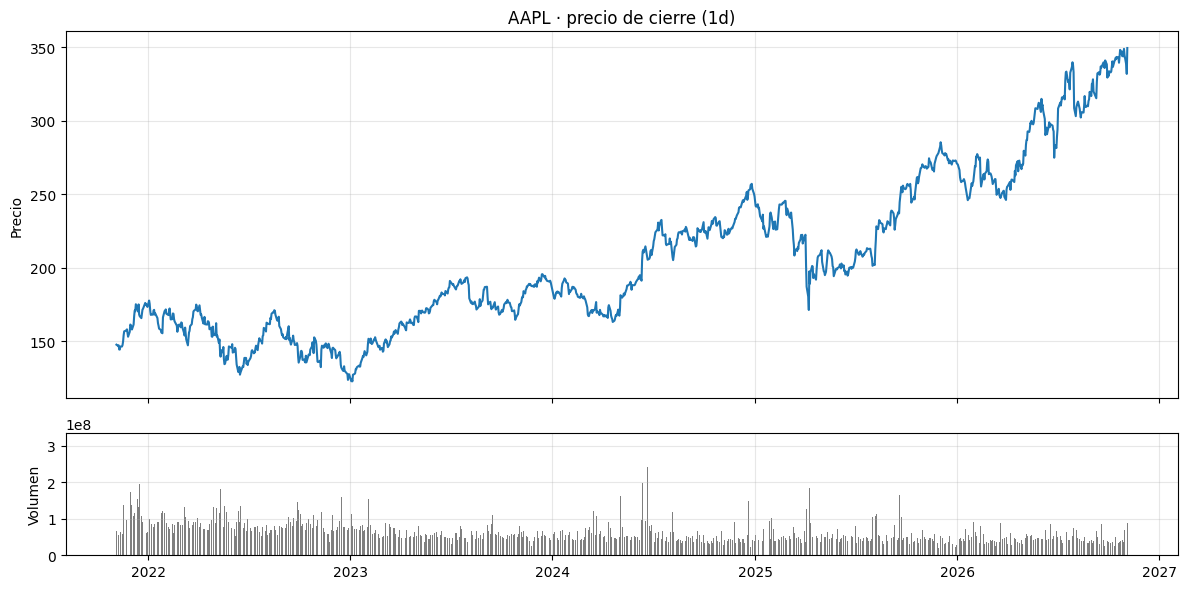

In [4]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ejes[0].plot(df.index, df["Close"], color="tab:blue")
ejes[0].set_title(f"{ticker} · precio de cierre ({interval})")
ejes[0].set_ylabel("Precio")
ejes[1].bar(df.index, df["Volume"], color="tab:gray")
ejes[1].set_ylabel("Volumen")
plt.tight_layout()
plt.show()

--- División cronológica ---
Entrenamiento:   877 (2021-11-05 → 2025-05-06)
Validación:      188 (2025-05-07 → 2026-02-04)
Prueba:          189 (2026-02-05 → 2026-11-04)


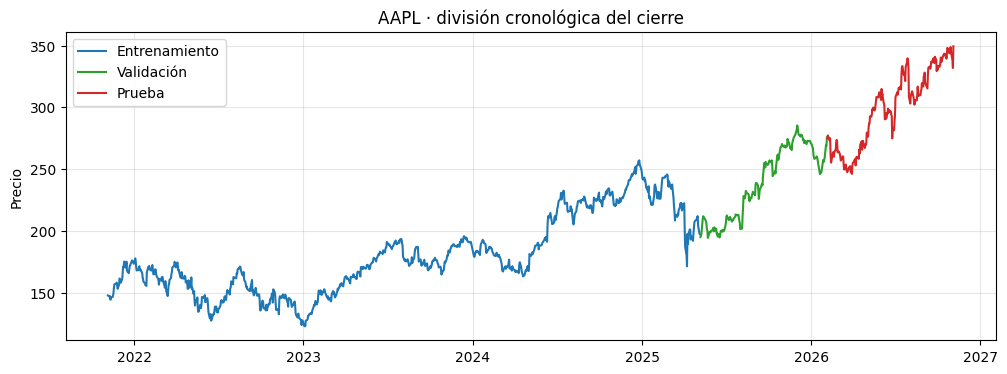

In [5]:
# Tabla de trabajo: el volumen (si se usa) pasa por log(1 + volumen) para comprimir los picos
datos = df[variables].copy()
if "Volume" in variables:
    datos["Volume"] = np.log1p(datos["Volume"])

raw_data = datos[variables].values.astype("float32")   # columna 0 = Close (objetivo)
fechas = datos.index
n_variables = raw_data.shape[1]

# División CRONOLÓGICA 70 / 15 / 15, sin mezclar
num_train = int(0.70 * len(raw_data))
num_val = int(0.15 * len(raw_data))
num_test = len(raw_data) - num_train - num_val
print("--- División cronológica ---")
print(f"Entrenamiento: {num_train:>5} ({fechas[0]:%Y-%m-%d} → {fechas[num_train - 1]:%Y-%m-%d})")
print(f"Validación:    {num_val:>5} ({fechas[num_train]:%Y-%m-%d} → {fechas[num_train + num_val - 1]:%Y-%m-%d})")
print(f"Prueba:        {num_test:>5} ({fechas[num_train + num_val]:%Y-%m-%d} → {fechas[-1]:%Y-%m-%d})")

plt.figure(figsize=(12, 4))
plt.plot(fechas[:num_train], raw_data[:num_train, 0], color="tab:blue", label="Entrenamiento")
plt.plot(fechas[num_train:num_train + num_val], raw_data[num_train:num_train + num_val, 0], color="tab:green", label="Validación")
plt.plot(fechas[num_train + num_val:], raw_data[num_train + num_val:, 0], color="tab:red", label="Prueba")
plt.title(f"{ticker} · división cronológica del cierre")
plt.ylabel("Precio")
plt.legend()
plt.show()

In [6]:
# Normalización con estadísticos SOLO del entrenamiento
media = raw_data[:num_train].mean(axis=0)
std = raw_data[:num_train].std(axis=0)
data_norm = (raw_data - media) / std
media_close, std_close = media[0], std[0]
print(f"Media del cierre (entrenamiento): {media_close:.2f} · desviación: {std_close:.2f}")

min_train, max_train = data_norm[:num_train, 0].min(), data_norm[:num_train, 0].max()
for nombre, tramo in [("Validación", data_norm[num_train:num_train + num_val, 0]), ("Prueba", data_norm[num_train + num_val:, 0])]:
    fuera = np.mean((tramo < min_train) | (tramo > max_train)) * 100
    print(f"{nombre}: {fuera:.1f} % de los precios fuera del rango de entrenamiento")

Media del cierre (entrenamiento): 179.52 · desviación: 31.19
Validación: 35.6 % de los precios fuera del rango de entrenamiento
Prueba: 89.9 % de los precios fuera del rango de entrenamiento


In [7]:
# Ventanas: cada ejemplo son `ventana` pasos; su objetivo es el cierre `horizonte` pasos después
delay = ventana + horizonte - 1
objetivo = data_norm[:, 0]

def crear_dataset(inicio, fin, mezclar=False):
    # Ventanas del tramo [inicio, fin): cada conjunto usa solo su propio periodo
    return keras.utils.timeseries_dataset_from_array(
        data_norm[:-horizonte], targets=objetivo[delay:], sequence_length=ventana,
        batch_size=batch_size, shuffle=mezclar, seed=SEED, start_index=inicio, end_index=fin)

train_ds = crear_dataset(0, num_train - horizonte, mezclar=True)
val_ds = crear_dataset(num_train, num_train + num_val - horizonte)
test_ds = crear_dataset(num_train + num_val, None)

for nombre, ds in [("Entrenamiento", train_ds), ("Validación", val_ds), ("Prueba", test_ds)]:
    print(f"{nombre:<14} {sum(x.shape[0] for x, _ in ds):>5} ventanas")

# Verificación manual con la primera ventana de prueba
x, y = next(iter(test_ds))
i0 = num_train + num_val
print(f"\nPrimera ventana de prueba: {fechas[i0]:%Y-%m-%d} → {fechas[i0 + ventana - 1]:%Y-%m-%d}")
print(f"Objetivo: cierre del {fechas[i0 + delay]:%Y-%m-%d} = {float(y[0]) * std_close + media_close:.2f} (tabla: {raw_data[i0 + delay, 0]:.2f})")

Entrenamiento    847 ventanas
Validación       158 ventanas
Prueba           159 ventanas

Primera ventana de prueba: 2026-02-05 → 2026-03-19
Objetivo: cierre del 2026-03-20 = 247.55 (tabla: 247.55)


## 2. Línea base


In [8]:
def evaluar_linea_base(dataset, metrica="mae"):
    # Error en dólares de predecir que el cierre futuro es igual al último cierre de la ventana
    error_total, n = 0.0, 0
    for muestras, objetivos in dataset:
        error = keras.ops.convert_to_numpy(muestras[:, -1, 0]) - keras.ops.convert_to_numpy(objetivos)
        error_total += (np.abs(error) if metrica == "mae" else error ** 2).sum()
        n += objetivos.shape[0]
    promedio = error_total / n
    return (promedio if metrica == "mae" else np.sqrt(promedio)) * std_close

mae_base_val = evaluar_linea_base(val_ds)
mae_base_test = evaluar_linea_base(test_ds)
rmse_base_test = evaluar_linea_base(test_ds, metrica="rmse")

registro = {"Línea base (mañana = hoy)": {"MAE val": mae_base_val, "MAE prueba": mae_base_test,
                                          "RMSE prueba": rmse_base_test, "Parámetros": 0}}
print(f"Línea base · MAE val {mae_base_val:.3f} · MAE prueba {mae_base_test:.3f} · RMSE prueba {rmse_base_test:.3f}")

Línea base · MAE val 2.303 · MAE prueba 3.745 · RMSE prueba 5.151


## 3. Modelo
**Red elegida: LSTM de 32 unidades** (Bloque 6, sección 1).

Por qué esta y no las otras recurrentes de la práctica:
- **LSTM simple:** fue de las mejores recurrentes del Bloque 6 y es la que el Bloque 8 usa para todos los experimentos por ser de las mejores y la más rápida (usa cuDNN).
- **LSTM con dropout recurrente:** pierde cuDNN, cada época es varias veces más lenta y no mejoró el MAE de prueba de forma clara.
- **GRU apilada:** el doble de capas y de parámetros sin ganancia clara; con ~800 ventanas de entrenamiento, más capacidad solo facilita el sobreajuste.
- **Bidireccional:** en pronóstico no ayuda, porque la dirección "hacia atrás" termina en el día más antiguo de la ventana, el menos útil para predecir mañana.

Se entrena con MSE, RMSprop, hasta 50 épocas y `EarlyStopping` (paciencia 8) que restaura los mejores pesos según la validación.

In [9]:
def obtener_callbacks(nombre, paciencia=8):
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, verbose=1),
            keras.callbacks.ModelCheckpoint(filepath=os.path.join(DIR_MODELOS, f"{nombre}.keras"),
                                            monitor="val_loss", save_best_only=True, verbose=0)]

def graficar_curvas(history, titulo=""):
    entr, val = history.history["mae"], history.history["val_mae"]
    mejor = int(np.argmin(val))
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, len(entr) + 1), entr, "o--", label="Entrenamiento (MAE)")
    plt.plot(range(1, len(val) + 1), val, "o-", label="Validación (MAE)")
    plt.axvline(mejor + 1, color="gray", linestyle=":", label=f"Mejor época: {mejor + 1}")
    plt.title(f"Curvas de aprendizaje · {titulo} (MAE normalizado)")
    plt.xlabel("Época")
    plt.legend()
    plt.show()

def entrenar_y_evaluar(modelo, nombre, epocas=50, paciencia=8):
    modelo.compile(optimizer="rmsprop", loss="mse", metrics=["mae"])
    inicio = time.perf_counter()
    historia = modelo.fit(train_ds, epochs=epocas, validation_data=val_ds,
                          callbacks=obtener_callbacks(nombre, paciencia), shuffle=False, verbose=0)
    n_ep = len(historia.history["loss"])
    graficar_curvas(historia, nombre)
    mae_val = modelo.evaluate(val_ds, verbose=0)[1] * std_close
    mse_test, mae_test = modelo.evaluate(test_ds, verbose=0)
    mae_test, rmse_test = mae_test * std_close, np.sqrt(mse_test) * std_close
    registro[nombre] = {"MAE val": mae_val, "MAE prueba": mae_test, "RMSE prueba": rmse_test,
                        "Parámetros": modelo.count_params()}
    print(f"--- {nombre} --- épocas: {n_ep} · {(time.perf_counter() - inicio) / n_ep:.2f} s/época")
    print(f"MAE prueba {mae_test:.3f} (línea base {mae_base_test:.3f}) · RMSE prueba {rmse_test:.3f} (línea base {rmse_base_test:.3f})")
    print(f"→ En prueba, la red {'SÍ' if mae_test < mae_base_test else 'NO'} supera a la línea base.")
    return modelo, historia

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Ventana (InputLayer)            │ (None, 30, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ LSTM_32 (LSTM)                  │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Cierre_futuro (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 42: early stopping
Restoring model weights from the end of the best epoch: 34.


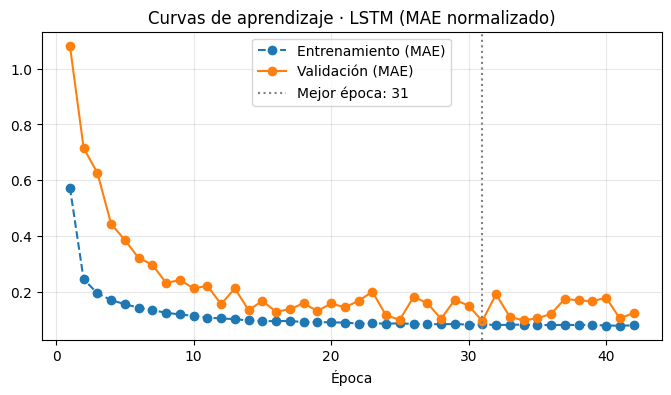

--- LSTM --- épocas: 42 · 2.40 s/época
MAE prueba 16.284 (línea base 3.745) · RMSE prueba 19.423 (línea base 5.151)
→ En prueba, la red NO supera a la línea base.


In [10]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(ventana, n_variables), name="Ventana")
x = layers.LSTM(32, name="LSTM_32")(inputs)
outputs = layers.Dense(1, name="Cierre_futuro")(x)
modelo_lstm = keras.Model(inputs, outputs, name="LSTM")
modelo_lstm.summary()
modelo_lstm, historia_lstm = entrenar_y_evaluar(modelo_lstm, "LSTM")

## 4. Resultados
Pronóstico **recursivo** de los próximos 30 días hábiles con `pronosticar_futuro()` y `dibujar_pronostico()` del Bloque 4: cada cierre predicho entra como si fuera real en la ventana siguiente. Si se usa volumen, el volumen futuro es el promedio de la última ventana. Al final, la tabla `resultados`.

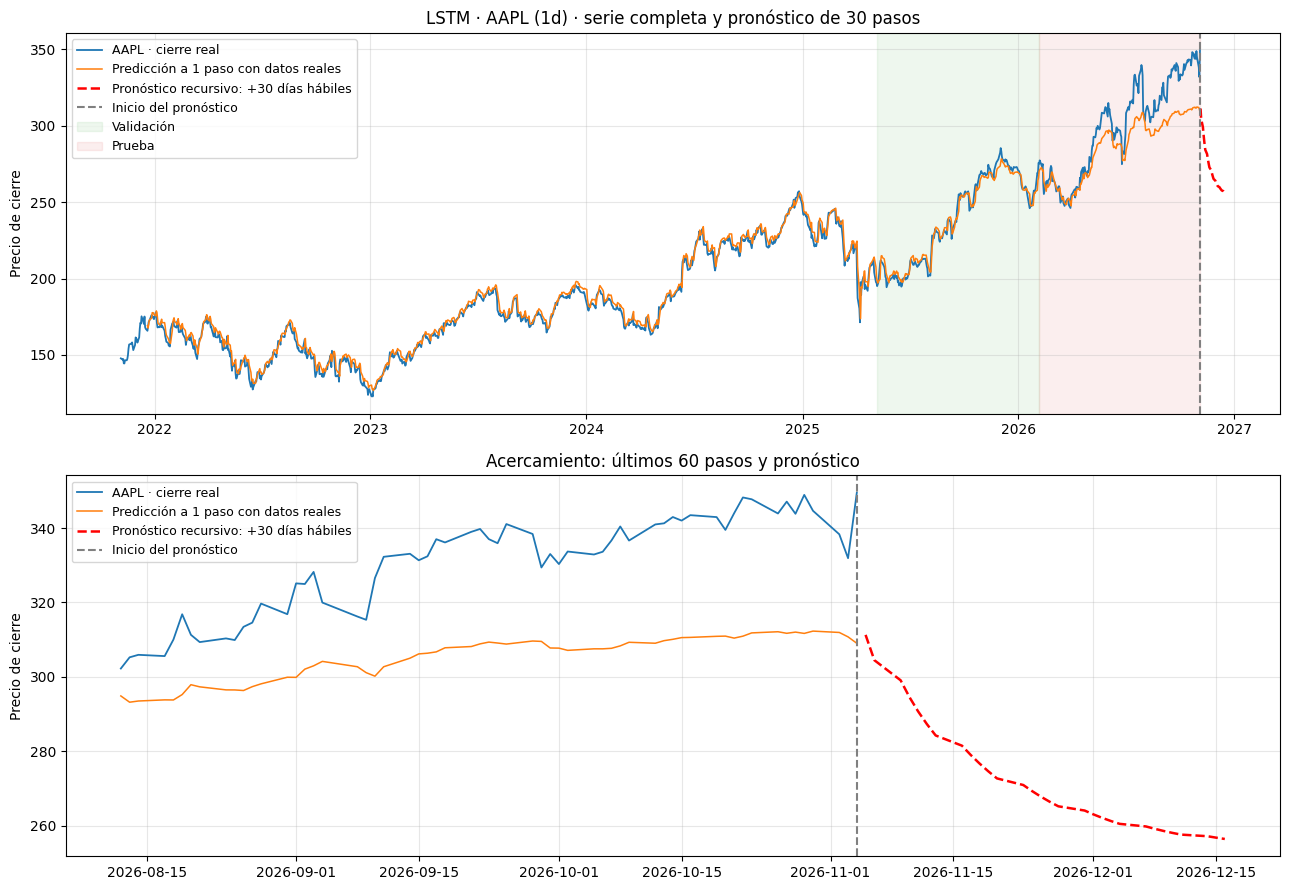

Último cierre conocido (2026-11-04): 349.51
Paso 1 (2026-11-05): 311.29 (-10.9 %)
Paso 30 (2026-12-16): 256.45 (-26.6 %)
Promedio del cierre en el entrenamiento: 179.52


In [11]:
pasos_futuro = 30

def fechas_futuras(pasos):
    if interval == "1d":
        return pd.bdate_range(fechas[-1] + pd.offsets.BDay(1), periods=pasos)   # días hábiles (no descuenta festivos)
    paso = fechas.to_series().diff().median()
    return pd.date_range(fechas[-1] + paso, periods=pasos, freq=paso)

def pronosticar_futuro(modelo, pasos=None):
    # Pronóstico RECURSIVO del cierre, en unidades de precio
    pasos = pasos or pasos_futuro
    n = len(data_norm)
    serie = np.concatenate([data_norm, np.zeros((pasos, n_variables), dtype="float32")])
    if n_variables > 1:
        serie[n:, 1] = data_norm[-ventana:, 1].mean()
    for t in range(n, n + pasos):
        fin = t - horizonte + 1
        serie[t, 0] = modelo.predict(serie[fin - ventana:fin][np.newaxis], verbose=0)[0, 0]
    return serie[n:, 0] * std_close + media_close

def dibujar_pronostico(nombre, pred_real, futuro, pasos_zoom=60):
    pasos = len(futuro)
    cierre = raw_data[:, 0]
    fechas_pred = fechas[delay:]
    fechas_fut = fechas_futuras(pasos)
    fig, ejes = plt.subplots(2, 1, figsize=(13, 9))
    for eje, desde in [(ejes[0], 0), (ejes[1], len(cierre) - pasos_zoom)]:
        d = max(desde - delay, 0)
        eje.plot(fechas[desde:], cierre[desde:], color="tab:blue", linewidth=1.3, label=f"{ticker} · cierre real")
        eje.plot(fechas_pred[d:], pred_real[d:], color="tab:orange", linewidth=1.1, label=f"Predicción a {horizonte} paso con datos reales")
        eje.plot(fechas_fut, futuro, "--", color="red", linewidth=1.8, label=f"Pronóstico recursivo: +{pasos} días hábiles")
        eje.axvline(fechas[-1], color="gray", linestyle="--", label="Inicio del pronóstico")
        eje.set_ylabel("Precio de cierre")
    ejes[0].axvspan(fechas[num_train], fechas[num_train + num_val - 1], color="tab:green", alpha=0.08, label="Validación")
    ejes[0].axvspan(fechas[num_train + num_val], fechas[-1], color="tab:red", alpha=0.08, label="Prueba")
    ejes[0].set_title(f"{nombre} · {ticker} ({interval}) · serie completa y pronóstico de {pasos} pasos")
    ejes[1].set_title(f"Acercamiento: últimos {pasos_zoom} pasos y pronóstico")
    for eje in ejes:
        eje.legend(loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()
    cambio = (futuro / cierre[-1] - 1) * 100
    print(f"Último cierre conocido ({fechas[-1]:%Y-%m-%d}): {cierre[-1]:.2f}")
    print(f"Paso 1 ({fechas_fut[0]:%Y-%m-%d}): {futuro[0]:.2f} ({cambio[0]:+.1f} %)")
    print(f"Paso {pasos} ({fechas_fut[-1]:%Y-%m-%d}): {futuro[-1]:.2f} ({cambio[-1]:+.1f} %)")
    print(f"Promedio del cierre en el entrenamiento: {media_close:.2f}")

pred_real = modelo_lstm.predict(crear_dataset(0, None), verbose=0)[:, 0] * std_close + media_close
futuro = pronosticar_futuro(modelo_lstm)
dibujar_pronostico("LSTM", pred_real, futuro)

In [12]:
resultados = pd.DataFrame(registro).T
resultados["MAE vs. línea base (%)"] = (resultados["MAE prueba"] / mae_base_test - 1) * 100
resultados = resultados[["MAE prueba", "RMSE prueba", "MAE vs. línea base (%)", "MAE val", "Parámetros"]].astype(float).round(3)
resultados

,MAE prueba,RMSE prueba,MAE vs. línea base (%),MAE val,Parámetros
Línea base (mañana = hoy),3.745,5.151,0.000,2.303,0.0
LSTM,16.284,19.423,334.784,3.055,4385.0


## 5. Conclusión


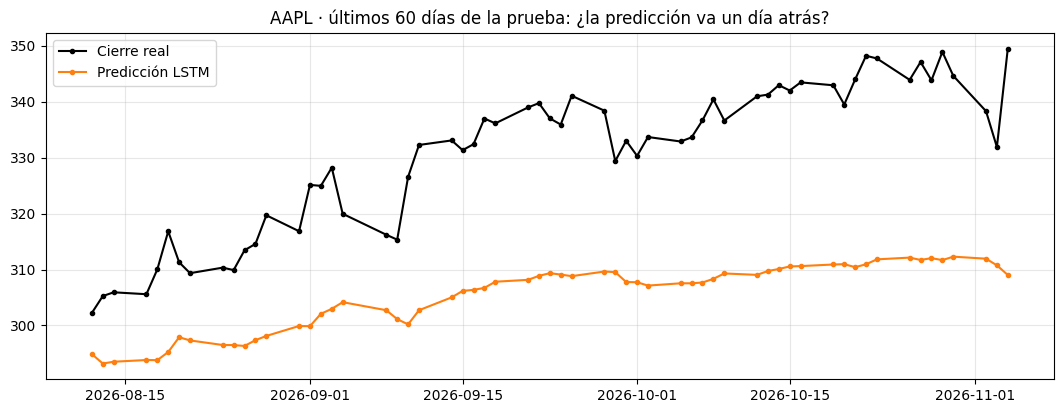

MAE contra el cierre REAL que debía predecir: 16.284
MAE contra el ÚLTIMO cierre que ya conocía:   15.353
Correlación entre el cambio predicho y el cambio real: +0.141


In [13]:
# 1. El "retraso de un día": ¿la red solo copia el último cierre?
def a_arreglos(dataset):
    X = np.concatenate([keras.ops.convert_to_numpy(x) for x, _ in dataset])
    y = np.concatenate([keras.ops.convert_to_numpy(y) for _, y in dataset])
    return X, y

desnorm = lambda v: v * std_close + media_close
X_test, y_test = a_arreglos(test_ds)
real = desnorm(y_test)
ultimo = desnorm(X_test[:, -1, 0])
pred = desnorm(modelo_lstm.predict(X_test, verbose=0)[:, 0])
fechas_obj = fechas[num_train + num_val + delay: num_train + num_val + delay + len(real)]

n_ver = 60
plt.figure(figsize=(13, 4.5))
plt.plot(fechas_obj[-n_ver:], real[-n_ver:], "o-", color="black", markersize=3, label="Cierre real")
plt.plot(fechas_obj[-n_ver:], pred[-n_ver:], "o-", color="tab:orange", markersize=3, label="Predicción LSTM")
plt.title(f"{ticker} · últimos {n_ver} días de la prueba: ¿la predicción va un día atrás?")
plt.legend()
plt.show()

mae_vs_real = np.mean(np.abs(pred - real))
mae_vs_ultimo = np.mean(np.abs(pred - ultimo))
corr_cambios = np.corrcoef(pred - ultimo, real - ultimo)[0, 1]
print(f"MAE contra el cierre REAL que debía predecir: {mae_vs_real:.3f}")
print(f"MAE contra el ÚLTIMO cierre que ya conocía:   {mae_vs_ultimo:.3f}")
print(f"Correlación entre el cambio predicho y el cambio real: {corr_cambios:+.3f}")

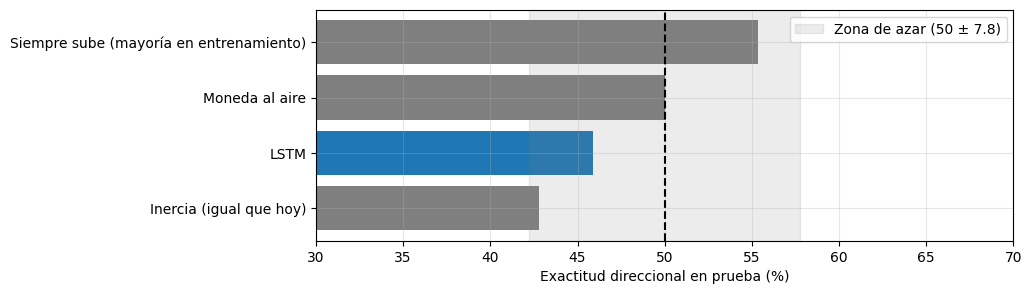

Días de prueba: 159 · zona compatible con el azar: 42.2 % a 57.8 %


,Exactitud direccional (%)
Inercia (igual que hoy),42.8
LSTM,45.9
Moneda al aire,50.0
Siempre sube (mayoría en entrenamiento),55.3


In [14]:
# 2. Exactitud direccional: ¿acierta si sube o baja?
X_tr, y_tr = a_arreglos(crear_dataset(0, num_train - horizonte))
clase_mayoritaria = (y_tr > X_tr[:, -1, 0]).mean() >= 0.5
real_sube = real > ultimo
hoy_subio = X_test[:, -1, 0] > X_test[:, -2, 0]

direccion = {
    "Moneda al aire": 50.0,
    f"Siempre {'sube' if clase_mayoritaria else 'baja'} (mayoría en entrenamiento)": np.mean(real_sube == clase_mayoritaria) * 100,
    "Inercia (igual que hoy)": np.mean(real_sube == hoy_subio) * 100,
    "LSTM": np.mean((pred > ultimo) == real_sube) * 100,
}
margen = 1.96 * np.sqrt(0.25 / len(real)) * 100   # intervalo del 95 % de una moneda al aire

tabla_dir = pd.Series(direccion, name="Exactitud direccional (%)").sort_values()
plt.figure(figsize=(9, 3))
plt.barh(tabla_dir.index, tabla_dir.values, color=["tab:blue" if n == "LSTM" else "tab:gray" for n in tabla_dir.index])
plt.axvspan(50 - margen, 50 + margen, color="gray", alpha=0.15, label=f"Zona de azar (50 ± {margen:.1f})")
plt.axvline(50, color="black", linestyle="--")
plt.xlim(30, 70)
plt.xlabel("Exactitud direccional en prueba (%)")
plt.legend()
plt.show()
print(f"Días de prueba: {len(real)} · zona compatible con el azar: {50 - margen:.1f} % a {50 + margen:.1f} %")
tabla_dir.round(1).to_frame()

In [15]:
# 3. Sesgo del pronóstico recursivo y veredicto
ultimo_cierre = raw_data[-1, 0]
cambio_30 = (futuro[-1] / ultimo_cierre - 1) * 100
dist_media = (ultimo_cierre / media_close - 1) * 100
hacia_media = np.sign(futuro[-1] - ultimo_cierre) == np.sign(media_close - ultimo_cierre)

gana_base = registro["LSTM"]["MAE prueba"] < mae_base_test
dir_util = direccion["LSTM"] > 50 + margen
señal = abs(corr_cambios) > 0.1

print(f"Último cierre: {ultimo_cierre:.2f} · promedio del entrenamiento: {media_close:.2f} ({dist_media:+.1f} % respecto al promedio)")
print(f"Pronóstico a 30 días hábiles: {futuro[-1]:.2f} ({cambio_30:+.1f} %)")
print(f"¿El pronóstico se mueve hacia el promedio del entrenamiento?: {'SÍ' if hacia_media else 'NO'}")
print()
print(f"¿La LSTM le gana a la línea base en MAE de prueba?: {'SÍ' if gana_base else 'NO'}")
print(f"¿Su exactitud direccional sale de la zona de azar?: {'SÍ' if dir_util else 'NO'} ({direccion['LSTM']:.1f} %)")
print(f"¿El cambio que predice se relaciona con el real?: {'SÍ' if señal else 'NO'} (correlación {corr_cambios:+.3f})")
puntos = sum([gana_base, dir_util, señal, not hacia_media])
confianza = "BAJA" if puntos <= 2 else ("MODERADA" if puntos == 3 else "ALTA (revisar: es raro en bolsa)")
print(f"\n→ El modelo dice que {ticker} {'SUBIRÁ' if cambio_30 > 0 else 'BAJARÁ'} ({cambio_30:+.1f} %) en 30 días hábiles. Confianza: {confianza}.")

Último cierre: 349.51 · promedio del entrenamiento: 179.52 (+94.7 % respecto al promedio)
Pronóstico a 30 días hábiles: 256.45 (-26.6 %)
¿El pronóstico se mueve hacia el promedio del entrenamiento?: SÍ

¿La LSTM le gana a la línea base en MAE de prueba?: NO
¿Su exactitud direccional sale de la zona de azar?: NO (45.9 %)
¿El cambio que predice se relaciona con el real?: SÍ (correlación +0.141)

→ El modelo dice que AAPL BAJARÁ (-26.6 %) en 30 días hábiles. Confianza: BAJA.


**Conclusión.** La LSTM pronostica que AAPL **bajará un 26.6 %** en los próximos 30 días hábiles, de 349.51 (cierre del 2026-11-04) a 256.45 (2026-12-16). **Mi confianza en esa conclusión es muy baja: la caída es un artefacto del modelo, no una señal del mercado.**

1. **La red no le gana a la línea base, ni de cerca.** En prueba, la LSTM tiene un MAE de **16.28** y un RMSE de **19.42**, contra **3.75** y **5.15** de «mañana = hoy»: se equivoca **335 % más** que no hacer nada. En validación la diferencia era mucho menor (MAE de 3.06 contra 2.30, +33 %). Ese salto entre validación y prueba es la clave del diagnóstico.
2. **La red no puede extrapolar.** El promedio del cierre en el entrenamiento es de 179.52 y la serie de entrenamiento nunca pasó de ~250, pero en la prueba AAPL subió hasta ~350. Una red neuronal solo "conoce" los valores que vio al entrenar: con entradas muy por encima de ese rango, su salida se satura. En la validación el precio aún estaba dentro de lo conocido y la red funcionaba casi como la línea base; en la prueba, la predicción con datos reales (naranja) se queda alrededor de 310 mientras el cierre real va en 340-350, un error sistemático de 30 a 40 dólares, siempre hacia abajo.
3. **El «retraso de un día» se rompe en la prueba.** En entrenamiento y validación, la predicción sigue a la real con el típico retraso de un día, casi encima de ella: la red aprendió en esencia «mañana = hoy». En la prueba ni eso: el primer paso del pronóstico (311.29) ya está 10.9 % debajo del último cierre, cuando la línea base diría 349.51. Una caída de 10.9 % en un día no tiene base en los datos; es el techo de la red.
4. **Sesgo del pronóstico recursivo.** Cada cierre predicho entra como si fuera real en la ventana siguiente. Como cada predicción sale por debajo de su entrada, el error se acumula y el pronóstico cae de forma continua hacia los precios que la red vio al entrenar. La caída de 26.6 % mide ese sesgo, no lo que hará AAPL.
5. **Dirección.** En los 159 días de prueba, la LSTM acierta si el precio sube o baja solo el **45.9 %** de las veces: dentro de la zona compatible con el azar (42.2 % a 57.8 %) y por debajo de lanzar una moneda (50 %). La regla trivial **"siempre sube"** (55.3 %) le gana por casi 10 puntos, porque en la prueba AAPL subió la mayoría de los días y la red, con su sesgo hacia abajo, predijo "baja" de más. La red no tiene información sobre la dirección del precio.

**¿Qué haría distinto?** Predecir el **rendimiento diario** en lugar del precio, que no depende del nivel del precio y no tiene este problema de extrapolación, o reentrenar con toda la serie antes de pronosticar. Aun así, con solo el pasado de la serie no hay información para saber si AAPL subirá o bajará en 30 días: la mejor estimación sigue siendo la línea base, "el precio se queda donde está".
